In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
episodes = pd.read_csv("../data/meta_100_episodes.csv")
units = pd.read_csv("../data/units_100_episodes.csv")

units.head()

,episode_id,t,team,unit_id,health,shield,alive,x,y,action,target_id
0,0,0,ally,0,45.0,0.0,True,8.250000,16.750000,4.0,NaN
1,0,0,ally,1,45.0,0.0,True,8.311523,16.000000,4.0,NaN
2,0,0,ally,2,45.0,0.0,True,9.000000,15.311523,4.0,NaN
3,0,0,ally,3,45.0,0.0,True,9.000000,16.000000,4.0,NaN
4,0,0,ally,4,45.0,0.0,True,9.000000,16.688477,4.0,NaN


In [6]:
agg = (units.groupby(["episode_id", "t", "team"])
            .agg(
                hp=("health", "sum"),
                alive=("alive", "sum")
            )
            .unstack("team"))


agg.head()

hp        alive      
team           ally  enemy  ally enemy
episode_id t                          
0          0  360.0  360.0     8     8
           1  360.0  360.0     8     8
           2  360.0  360.0     8     8
           3  360.0  360.0     8     8
           4  360.0  360.0     8     8

In [7]:
agg.columns = [f"{q}_{team}" for q, team in agg.columns]   # hp_ally, hp_enemy, alive_ally, alive_enemy
agg = agg.reset_index()

In [8]:
agg.head()

,episode_id,t,hp_ally,hp_enemy,alive_ally,alive_enemy
0,0,0,360.0,360.0,8,8
1,0,1,360.0,360.0,8,8
2,0,2,360.0,360.0,8,8
3,0,3,360.0,360.0,8,8
4,0,4,360.0,360.0,8,8


In [9]:
final = agg.groupby("episode_id").last() #Returns the final state of each simulation.

0.97
       alive_ally  alive_enemy
count  100.000000   100.000000
mean     4.360000     0.030000
std      1.132798     0.171447
min      1.000000     0.000000
25%      4.000000     0.000000
50%      4.000000     0.000000
75%      5.000000     0.000000
max      7.000000     1.000000


<Axes: xlabel='Allies surviving'>

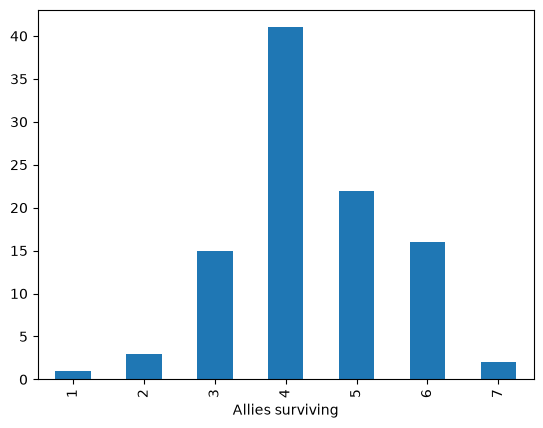

In [10]:
print(episodes["battle_won"].mean())                 # win rate
print(final[["alive_ally", "alive_enemy"]].describe())
final["alive_ally"].value_counts().sort_index().plot.bar(xlabel="Allies surviving")

In [11]:
start = agg.groupby("episode_id")[["hp_ally", "hp_enemy"]].transform("first")
hit = (agg.hp_ally < start.hp_ally) | (agg.hp_enemy < start.hp_enemy)
contact = agg[hit].groupby("episode_id")["t"].min().rename("t_contact")
agg = agg.merge(contact, on="episode_id")
fight = agg[agg.t >= agg.t_contact - 1].copy()       # keep one step before contact
fight["tau"] = fight.t - fight.t_contact

In [12]:
fight.loc[agg['episode_id']==0]

,episode_id,t,hp_ally,hp_enemy,alive_ally,alive_enemy,t_contact,tau
13,0,13,360.0,360.0,8,8,14,-1
14,0,14,348.0,342.0,8,8,14,0
15,0,15,348.0,342.0,8,8,14,1
16,0,16,342.0,342.0,8,8,14,2
17,0,17,336.0,342.0,8,8,14,3
...,...,...,...,...,...,...,...,...
93,0,93,90.0,9.0,4,1,14,79
94,0,94,90.0,9.0,4,1,14,80
95,0,95,90.0,3.0,4,1,14,81
96,0,96,90.0,3.0,4,1,14,82


In [13]:
g = fight.groupby("episode_id")
fight["loss_ally"]  = fight.hp_ally  - g.hp_ally.shift(-1)
fight["loss_enemy"] = fight.hp_enemy - g.hp_enemy.shift(-1)

In [14]:
fight

,episode_id,t,hp_ally,hp_enemy,alive_ally,alive_enemy,t_contact,tau,loss_ally,loss_enemy
13,0,13,360.0,360.0,8,8,14,-1,12.0,18.0
14,0,14,348.0,342.0,8,8,14,0,0.0,0.0
15,0,15,348.0,342.0,8,8,14,1,6.0,0.0
16,0,16,342.0,342.0,8,8,14,2,6.0,0.0
17,0,17,336.0,342.0,8,8,14,3,0.0,6.0
...,...,...,...,...,...,...,...,...,...,...
9619,99,95,114.0,15.0,4,1,13,82,0.0,6.0
9620,99,96,114.0,9.0,4,1,13,83,0.0,0.0
9621,99,97,114.0,9.0,4,1,13,84,6.0,0.0
9622,99,98,108.0,9.0,4,1,13,85,0.0,9.0


Pivot table for enemy

alive_enemy    1    2    3    4    5    6    7    8
alive_ally                                         
1            0.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN
2            0.6  1.6  NaN  NaN  NaN  NaN  NaN  NaN
3            0.7  1.4  2.6  3.0  NaN  NaN  NaN  NaN
4            0.8  1.5  1.8  3.0  NaN  NaN  NaN  NaN
5            0.7  1.5  2.4  3.2  3.4  3.4  NaN  NaN
6            0.7  1.6  2.3  3.1  3.7  4.2  NaN  NaN
7            0.9  1.5  2.3  3.1  4.0  4.7  5.6  NaN
8            NaN  1.3  3.0  3.4  4.0  5.0  5.3  4.2


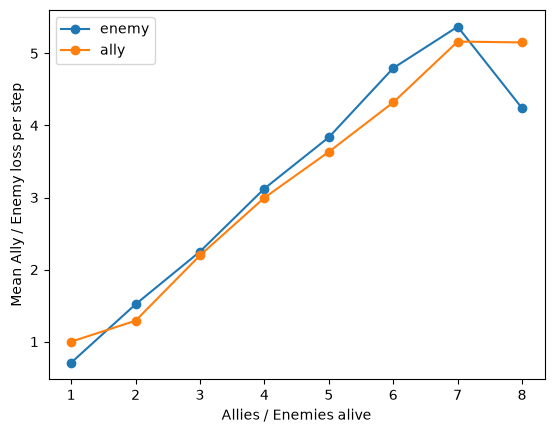

In [15]:
print("Pivot table for enemy\n")

table = fight.pivot_table(values="loss_ally", index="alive_ally",
                          columns="alive_enemy", aggfunc="mean")
print(table.round(1))




# table = fight.pivot_table(values="loss_enemy", index="alive_enemy",
#                           columns="alive_ally", aggfunc="mean")
# print(table.round(1))

plt.plot(fight.groupby("alive_enemy")["loss_ally"].mean(),label="enemy", marker="o")
plt.plot(fight.groupby("alive_ally")["loss_enemy"].mean(), label = "ally", marker="o")
plt.xlabel("Allies / Enemies alive")
plt.ylabel("Mean Ally / Enemy loss per step")
plt.legend()
plt.show()

In [25]:
import pysindy as ps

n, hp_max = 8, 8 * 45
cols = ["alive_ally", "alive_enemy", "hp_ally", "hp_enemy"]
scale = np.array([n, n, hp_max, hp_max])
trajs = [d.sort_values("t")[cols].to_numpy(float) / scale
         for _, d in fight.groupby("episode_id")]



model = ps.SINDy(feature_library=ps.PolynomialLibrary(degree=2),
                 optimizer=ps.STLSQ(threshold=0.02))
model.fit(trajs,t=1, feature_names=["Na", "Nb", "Ha", "Hb"])          # older PySINDy versions: model.fit(trajs, multiple_trajectories=True)
model.print()

(Na)' =  0.057 Na + -0.091 Ha + -0.043 Hb + -0.060 Na^2 +  0.007 Na Ha +  0.118 Na Hb + -0.105 Nb Ha +  0.085 Nb Hb +  0.177 Ha^2 + -0.143 Ha Hb
(Nb)' = -0.103 Na +  0.141 Nb + -0.003 Ha +  0.044 Na^2 +  0.367 Na Nb +  0.026 Na Ha + -0.479 Na Hb + -1.666 Nb^2 +  1.130 Nb Ha +  1.867 Nb Hb + -0.408 Ha^2 + -0.307 Ha Hb + -0.620 Hb^2
(Ha)' =  0.044 Na^2 + -0.166 Na Ha +  0.113 Ha^2
(Hb)' = -0.021 Ha


In [29]:
n, hp_max = 8, 8 * 45
X, U = [], []
for _, d in fight.groupby("episode_id"):
    d = d.sort_values("t")
    end = d.index[(d.alive_ally == 0) | (d.alive_enemy == 0)]
    if len(end):                                   # stop at the first wipe-out
        d = d.loc[:end[0]]
    if len(d) < 3:
        continue
    X.append(d[["hp_ally", "hp_enemy"]].to_numpy(float) / hp_max)
    U.append(d[["alive_ally", "alive_enemy"]].to_numpy(float) / n)

model = ps.DiscreteSINDy(feature_library=ps.PolynomialLibrary(degree=1),
                         optimizer=ps.STLSQ(threshold=0.01))
model.fit(X, t=1, u=U, feature_names=["Ha", "Hb", "Na", "Nb"])
model.print()

(Ha)[k+1] =  0.997 Ha[k] + -0.013 Nb[k]
(Hb)[k+1] =  0.027 Ha[k] +  0.974 Hb[k] + -0.028 Na[k] +  0.013 Nb[k]


[array([[1.        , 1.        ],
        [0.96666667, 0.95      ],
        [0.96666667, 0.95      ],
        [0.95      , 0.95      ],
        [0.93333333, 0.95      ],
        [0.93333333, 0.93333333],
        [0.93333333, 0.91666667],
        [0.91666667, 0.91666667],
        [0.91666667, 0.875     ],
        [0.88333333, 0.875     ],
        [0.88333333, 0.875     ],
        [0.85      , 0.875     ],
        [0.85      , 0.84166667],
        [0.83333333, 0.825     ],
        [0.83333333, 0.825     ],
        [0.8       , 0.825     ],
        [0.76666667, 0.75833333],
        [0.76666667, 0.74166667],
        [0.73333333, 0.74166667],
        [0.73333333, 0.70833333],
        [0.71666667, 0.70833333],
        [0.71666667, 0.69166667],
        [0.68333333, 0.69166667],
        [0.66666667, 0.66666667],
        [0.65      , 0.63333333],
        [0.63333333, 0.61666667],
        [0.63333333, 0.60833333],
        [0.61666667, 0.60833333],
        [0.61666667, 0.60833333],
        [0.575

In [27]:
model.coefficients()

array([[ 0.        ,  0.99683485,  0.        ,  0.        , -0.01267806],
       [ 0.        ,  0.02749101,  0.9739881 , -0.02786738,  0.01270865]])

In [30]:
   Xall = np.vstack([np.hstack([x, u]) for x, u in zip(X, U)])
   print(np.round(np.corrcoef(Xall.T), 2))   # order: Ha, Hb, Na, Nb

[[1.   0.98 0.86 0.95]
 [0.98 1.   0.85 0.98]
 [0.86 0.85 1.   0.85]
 [0.95 0.98 0.85 1.  ]]


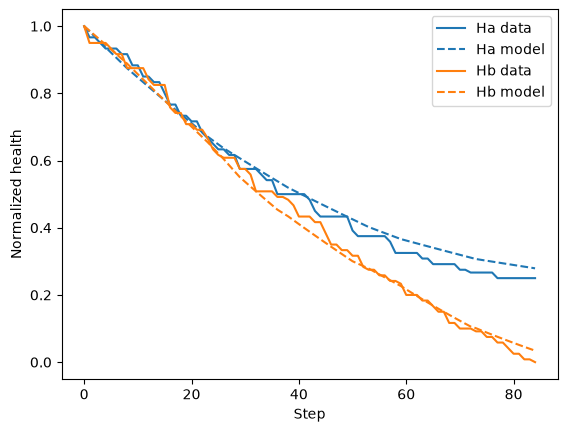

In [31]:
import matplotlib.pyplot as plt

i = 0                                            # pick an episode
sim = model.simulate(X[i][0], t=len(X[i]), u=U[i])

fig, ax = plt.subplots()
ax.plot(X[i][:, 0], "C0", label="Ha data");  ax.plot(sim[:, 0], "C0--", label="Ha model")
ax.plot(X[i][:, 1], "C1", label="Hb data");  ax.plot(sim[:, 1], "C1--", label="Hb model")
ax.set_xlabel("Step"); ax.set_ylabel("Normalized health"); ax.legend(); plt.show()

In [32]:
def closed_loop(model, x0, n=8, max_steps=300):
    x, traj = np.array(x0, float), [np.array(x0, float)]
    for _ in range(max_steps):
        u = np.ceil(np.clip(x, 0, 1) * n) / n            # units alive, from health
        x = model.predict(x.reshape(1, -1), u=u.reshape(1, -1))[0]
        traj.append(x)
        if (x <= 0).any():                               # one side wiped out
            break
    return np.array(traj)

pred = closed_loop(model, X[i][0])

In [33]:
idx = np.random.default_rng(0).permutation(len(X))
train, test = idx[:70], idx[70:]

model.fit([X[j] for j in train], t=1, u=[U[j] for j in train],
          feature_names=["Ha", "Hb", "Na", "Nb"])

results = []
for j in test:
    p = closed_loop(model, X[j][0])
    results.append(dict(
        true_win=X[j][-1, 1] <= 0.01,        # did the enemy end at ~zero health?
        pred_win=p[-1, 1] <= 0,
        true_Ha=X[j][-1, 0], pred_Ha=max(p[-1, 0], 0),
        true_len=len(X[j]), pred_len=len(p)))
res = pd.DataFrame(results)
print("Winner accuracy:", (res.true_win == res.pred_win).mean())
print(res[["true_Ha", "pred_Ha", "true_len", "pred_len"]].describe())

Winner accuracy: 0.03333333333333333
         true_Ha  pred_Ha    true_len  pred_len
count  30.000000     30.0   30.000000      30.0
mean    0.276944      0.0   84.000000     144.0
std     0.053053      0.0    9.421179       0.0
min     0.150000      0.0   68.000000     144.0
25%     0.243750      0.0   76.000000     144.0
50%     0.287500      0.0   83.500000     144.0
75%     0.322917      0.0   90.000000     144.0
max     0.350000      0.0  109.000000     144.0
